In [1]:
from torchvision import transforms
from torch.utils.data import Dataset, DataLoader
import numpy as np
import torch
import torchvision
import torchvision.transforms as transforms
import matplotlib.pyplot as plt
import torch.nn as nn
import torch.nn.functional as F
import torch.optim as optim
from sklearn.model_selection import train_test_split
import time
from PIL import Image
import os, json, pandas as pd, matplotlib.pyplot as plt

d:\Anaconda\install\envs\pytorch\lib\site-packages\tqdm\auto.py:21: TqdmWarning: IProgress not found. Please update jupyter and ipywidgets. See https://ipywidgets.readthedocs.io/en/stable/user_install.html
  from .autonotebook import tqdm as notebook_tqdm


**1. Path Defination**

In [2]:
# User-defined paths
home_path = r'D:\2023_second_half\transtip_evaluation\TransTip_Dataset\transtip_pose'
data_dir = os.path.join(home_path, "trans_no_markers_circle", "edge_3d")
train_dir =  os.path.join(data_dir, "train") 
valid_dir =  os.path.join(data_dir, "test") 
test_dir =  os.path.join(data_dir, "test") 
model_dir =  os.path.join(train_dir, "train2d_densenet_edge3d_trans")
test_result_dir = os.path.join(test_dir, "test2d_densenet_edge3d_trans")

os.makedirs(test_result_dir, exist_ok=True)
os.makedirs(os.path.join(home_path, model_dir), exist_ok=True)


**2. GPU Checking**

In [3]:

def check_gpu(gpu_index=0):
    torch.cuda.set_device(gpu_index) ## GPU (0)
    device_count = torch.cuda.device_count() # 可用的GPU数量
    current_device = torch.cuda.current_device() #返回当前所选设备的索引
    device_name = torch.cuda.get_device_name(current_device) #返回设备名， 默认值为当前设备
    device_capability = torch.cuda.get_device_capability(current_device) # 设备的最大和最小的cuda容量, 默认值为当前设备
    device_properties = torch.cuda.get_device_properties(current_device)
    # device_properties = torch.cuda.get_device_properties(0)
    is_available = torch.cuda.is_available() # 当前CUDA是否可用
    # device_cuda = torch.device("cuda") # GPU设备

    print('device_count: {device_count}'.format(device_count=device_count))
    print('current_device: {current_device}'.format(current_device=current_device))
    print('device_name: {device_name}'.format(device_name=device_name))
    print('device_capability: {device_capability}'.format(device_capability=device_capability))
    print('device_properties: {device_properties}'.format(device_properties=device_properties))
    print('is_available: {is_available}'.format(is_available=is_available))

**3. Dataset Defination**

In [4]:
#定义读取文件的格式
def default_loader(path):  ## 定义img读取函数，在PIL中，使用Image模块的open()函数打开
    return Image.open(path).convert('RGB')  ## 彩色图像模式为RGB
    # return Image.open(path).convert('L')  ## 灰度图片模式为L
    
#图像的初始化操作
data_transforms = transforms.Compose([
    # transforms.Grayscale(num_output_channels=1),   ## 转灰度图 
    transforms.Resize([256,256]),  ## 改变尺寸
    transforms.ToTensor(),  ## ToTensor()能够把灰度范围从0-255变换到0-1之间
    # transforms.Normalize([0.5], [0.5])  ## Normalize()则把0-1变换到(-1,1)
])


class MyDataset(Dataset):  ## 继承自torch的Dataset

    def __init__(self, file_path, imgs_path, transform=data_transforms, loader=default_loader):  ## 定义初始化函数
        super(MyDataset, self).__init__()  ## 对继承自父类的属性进行初始化
        self.file_path = file_path   ## csv文件路径
        self.imgs_path = imgs_path   ## 原始图片路径
        # data_list = []
        self.transform = transform  ## 对原始图片进行处理
        self.loader = loader
        # self.data_list = data_list
        csv_file_name = self.file_path + '/targets.csv'
        self.raw_data_label = pd.read_csv(csv_file_name, header=0, usecols=['image_name', 'pose_1', 'pose_3', 'pose_6'])  ## read label.csv file
        self.data_label = np.array([self.raw_data_label['image_name'].values,
                       self.raw_data_label['pose_1'].values,
                       self.raw_data_label['pose_3'].values,
                       self.raw_data_label['pose_6'].values])
        self.data_label = self.data_label.T  ## images index with labels (pose2--Y & pose6--Theta_roll)

    def __getitem__(self, index):   ## 枚举Index，根据上述data_list的列表信息，读取对应的图片与label

        img_dir = self.imgs_path + '/' + self.data_label[index][0] ## image dir
        label = [self.data_label[index][1], self.data_label[index][2], self.data_label[index][3]]  ## pose label
        
        label = torch.as_tensor(label) # 数据标签转换为Tensor
        
        img = self.loader(img_dir)  # 按照路径读取图片，利用上方定义的default_loader函数
        
        if self.transform is not None:
            img = self.transform(img)    # data tranformation

        return img, label  # return回哪些内容，那么我们在训练时循环读取每个batch时，就能获得哪些内容

    def __len__(self):  ## #这个函数也必须要写，它返回的是数据集的长度，也就是多少张图片，要和loader的长度作区分
        return len(self.data_label)

**4. Dataset loading**

In [5]:
img_path = data_dir + '/' + 'frames_bw'

train_img_data = MyDataset(train_dir, img_path)
valid_img_data = MyDataset(valid_dir, img_path)
test_img_data = MyDataset(valid_dir, img_path)

print('Num_of_Train_Data:', len(train_img_data))
print('Num_of_Valid_Data:', len(valid_img_data))
print('Num_of_Test_Data:', len(test_img_data))

batch_size = 24
train_loader = DataLoader(train_img_data, batch_size, shuffle=True, num_workers=0)
val_loader = DataLoader(valid_img_data, batch_size, shuffle=True, num_workers=0)
test_loader = DataLoader(test_img_data, batch_size=1, shuffle=False, num_workers=0)

Num_of_Train_Data: 2219
Num_of_Valid_Data: 781
Num_of_Test_Data: 781


**5. Function Defination**

In [6]:
def plot_pred(pred_df, target_names, poses_rng, **kwargs):

    plt.rcParams.update({'font.size': 18+2})
    n = len(target_names)
    fig, axes = plt.subplots(ncols=n, figsize=(7*n, 7), dpi = 500)

    fig.subplots_adjust(wspace=0.3)
    n_smooth = int(pred_df.shape[0]/20)    

    for i, ax in enumerate(axes): 

        sort_df = pred_df.sort_values(by=[f"target_{i+1}"])
        ax.scatter(sort_df[f"target_{i+1}"], sort_df[f"pred_{i+1}"], s=1, c = 'k', cmap="inferno") ##c=sort_df[f"target_{i+1}"], 
        ax.plot(sort_df[f"target_{i+1}"].rolling(n_smooth).mean(), sort_df[f"pred_{i+1}"].rolling(n_smooth).mean(), c="red")
        # ax.set(xlabel=f"target {target_names[i]}", ylabel=f"predicted {target_names[i]}")
        # ax.set(xlabel=r"Target $X$ (mm)" if i == 0 else r"Target $\theta_{Roll}$ (°)", ylabel=r"Predicted $X$ (mm)" if i == 0 else r"Predicted $\theta_{Roll}$ (°)")
        if i==0:
           ax.set(xlabel=r"Target $X$ (mm)", ylabel=r"Predicted $X$ (mm)")
        if i==1:
           ax.set(xlabel=r"Target $Z$ (mm)", ylabel=r"Predicted $Z$ (mm)")
        if i==2:
           ax.set(xlabel=r"Target $\theta_{Roll}$ (°)", ylabel=r"Predicted $\theta_{Roll}$ (°)")
        
        ind = int(target_names[i][-1])-1
        ax.set_xlim(poses_rng[0][ind], poses_rng[1][ind])
        ax.set_ylim(poses_rng[0][ind], poses_rng[1][ind])
        ax.text(0.05,0.9, 'MAE='+str(sort_df[f"error_{i+1}"].mean())[0:4], transform=ax.transAxes)    
        ax.grid(True)

    return fig



class Densenet_model:
    def __init__(self):
        self._model = None
        
    # build CNN model
    def build_model(self):
    
        # DEVICE = torch.device("cuda:1" if torch.cuda.is_available() else "cpu")
        DEVICE = torch.device("cuda" if torch.cuda.is_available() else "cpu")  # Cpu or Gpu?
        torch.cuda.empty_cache()

        model = torchvision.models.densenet121(pretrained=False)
        model.classifier = nn.Sequential(
                    nn.Linear(1024, 256), 
                    nn.LeakyReLU(),
                    nn.Linear(256, 3)
                    )  ## densenet output

        model.to(DEVICE)

        return model, DEVICE


    def train(self,model, device, train_loader, optimizer, epoch, pose_1_norm, pose_3_norm, pose_6_norm, batch_size, history, criterion):

        model.train()
        start = time.time()
        train_loss = 0.0
        train_total = 0
        train_batch_num = 0.0

        for batch_idx, (data, target) in enumerate(train_loader):

            data, target = data.to(device), target.to(device)
            optimizer.zero_grad()
            output = model(data)

            out_norm = output*torch.tensor([pose_1_norm, pose_3_norm, pose_6_norm]).cuda() ## output normalization

            label_norm = (target).view(output.size())*torch.tensor([pose_1_norm, pose_3_norm, pose_6_norm]).cuda()  ## target normalization

            loss = criterion(out_norm, label_norm)  ## calculate loss    

            loss.backward()  ## backward

            optimizer.step()  ## parameter update bt optimizer

            train_loss += loss.cpu().item()  ## Loss add

            train_total += 1  ## update train times 

            train_batch_num += 1  ## update batch number 

            if (batch_idx + 1) % 1 == 0:
                progress_bar = '[' + ('=' * ((batch_idx + 1) // 10)) + (' ' * ((len(train_img_data) // 100 - (batch_idx + 1)) // 10)) + ']'
                print('\repoch: {:d} training loss: {:.5f} {}'
                      .format(epoch + 1, loss.cpu().item(), progress_bar), end="  ")  ## live Loss

        time_cost = time.time() - start
        print('\repoch: {:d} train loss: {:.5f} training time: {:.1f} s/epoch'
              .format(epoch + 1, train_loss / train_batch_num, time_cost), end="  ")  # current epoch avrage Loss of each batch

        history["train_loss"].append(train_loss / train_batch_num)  ## record train loss



    def val(self, model, device, val_loader, pose_1_norm, pose_3_norm, pose_6_norm, history, scheduler, optimizer, train_data_dir, erro, criterion):

        model.eval()
        val_batch_num = 0
        val_loss = 0

        with torch.no_grad():

            for data, target in val_loader:

                data, target = data.to(device), target.to(device)
                
                output = model(data)

                out_norm = output*torch.tensor([pose_1_norm, pose_3_norm, pose_6_norm]).cuda()

                label_norm = (target).view(output.size())*torch.tensor([pose_1_norm, pose_3_norm, pose_6_norm]).cuda()

                val_loss += criterion(out_norm, label_norm)  ## Valid Loss

                val_batch_num += 1

        
        print(f'Valid Loss: {val_loss / val_batch_num:.5f}', end='  ')  ## val loss

        history["val_loss"].append(float(val_loss / val_batch_num))  ## record val loss


        scheduler.step(val_loss.cpu().item() / val_batch_num)  # learning rate update

        LR_ = optimizer.param_groups[0]['lr']  ## new learning rate

        print('\n' + f'learning rate: {LR_:.8f}', end='  ')  


        if (val_loss / val_batch_num) < erro:  ## save the best model from all epoch

            erro = val_loss / val_batch_num

            model_dir = train_data_dir + '/best_model.pth'

            torch.save(model.state_dict(), model_dir)   

            print('\n' + 'Saving model......' + '\n')
     
    
    def test(self, model, device, test_loader, criterion, pose_1_norm, pose_3_norm, pose_6_norm, model_dir, test_result_dir):

        test_loss = 0
        batch_num = 0
        
        meta_list = [{'pred_1':'', 'target_1':'', 'error_1':'','pred_2':'','target_2':'','error_2':'','pred_3':'','target_3':'','error_3':'',}] 
        df = pd.DataFrame(meta_list, columns = ['pred_1', 'target_1','error_1','pred_2','target_2','error_2','pred_3','target_3','error_3'])  ## record prediction details

        model.eval()  ## set as evaluation mode

        model_file = model_dir + r'/best_model.pth'  ## best model in training

        with torch.no_grad(): 

            for batch_idx, (data, target) in enumerate(test_loader):

                data, target = data.to(device), target.to(device)

                model.load_state_dict(torch.load(model_file, map_location='cuda:0'))  ## load in best model

                output = model(data)

                out_norm = output*torch.tensor([pose_1_norm, pose_3_norm, pose_6_norm]).cuda() ## output normalization

                label_norm = (target).view(output.size())*torch.tensor([pose_1_norm, pose_3_norm, pose_6_norm]).cuda()  ## target normalization

                # label = (target).view(output.size()) ## target normalization

                test_loss += criterion(out_norm, label_norm)  ## calculate loss    

                pred_1 = (out_norm.cpu())[0][0]  ## pred pose_2--Y
                pred_2 = (out_norm.cpu())[0][1]  ## pred pose_6--Theta_roll
                pred_3 = (out_norm.cpu())[0][2]  ## pred pose_6--Theta_roll

                target_1 = (label_norm)[0][0]  ## true pose_1--X
                target_2 = (label_norm)[0][1]  ## true pose_6--Theta_roll 
                target_3 = (label_norm)[0][2]  ## true pose_6--Theta_roll 

                error_1 = abs(pred_1 - target_1)  ## error pose_1--X
                error_2 = abs(pred_2 - target_2)  ## error pose_6--Theta_roll
                error_3 = abs(pred_3 - target_3)  ## error pose_6--Theta_roll

                df.loc[batch_num] = [pred_1.cpu(), target_1.cpu(), error_1.cpu(), \
                                     pred_2.cpu(), target_2.cpu(), error_2.cpu(), \
                                     pred_3.cpu(), target_3.cpu(), error_3.cpu()]  ## write prediction details

                batch_num += 1

                if (batch_idx + 1) % 1 == 0:
                    progress_bar = '[' + ('=' * ((batch_idx + 1) // 10)) + (' ' * ((len(test_img_data) // 100 - (batch_idx + 1)) // 10)) + ']'
                    print('\repoch: {:d} training loss: {:.5f} {}'
                        .format(1, test_loss.cpu().item()/(batch_idx + 1), progress_bar), end="  ")  ## live Loss


        print(f'Test Loss: {test_loss / batch_num:.5f}', end='  ')  ## Test loss

        test_pred_file_dir = os.path.join(test_result_dir, 'prediction.csv')

        df.to_csv(test_pred_file_dir)  ## save prediction details as csv file
        
        ## plot the test results
        fig = plot_pred(pred_df = df, target_names = ["pose_1", "pose_3", "pose_6"], poses_rng = [[5, 0, 1, 0, 0, 45], [-5, 0, -1, 0, 0, -45]])
        fig.savefig(os.path.join(test_result_dir, "errors.png"), bbox_inches='tight') 

**6. Training**

In [7]:
check_gpu(gpu_index=0)
densenet = Densenet_model()
Model, DEVICE = densenet.build_model()
Model.to(DEVICE)

epoch_num=40
criterion = nn.MSELoss()  ## MAE Loss
optimizer = optim.Adam(Model.parameters(), lr=0.0003)
scheduler = torch.optim.lr_scheduler.ReduceLROnPlateau(optimizer, mode='min', factor=0.5, patience=5, verbose=True,
                                                        threshold=0.001, threshold_mode='rel',
                                                        cooldown=0, min_lr=0, eps=1e-08)  ## learning rate adapter setting

print('Start Train')

erro = 10000  ## initialise error value to max
pose_1_norm = 1  ## pose_2 norm scale
pose_3_norm = 1  ## pose_2 norm scale
pose_6_norm = 1  ## pose_6 norm scale

history = {
        "train_loss": [],
        "val_loss": []
    }  ## training history recording

for epoch in range(epoch_num):

    train_loss = 0.0
    train_total = 0
    train_batch_num = 0.0

    print('{:.0f} Epochs Training Start'.format(epoch+1), end = ' ')
    

    densenet.train(model=Model, device=DEVICE, train_loader=train_loader, \
                   optimizer=optimizer, epoch=epoch, pose_1_norm=pose_1_norm, pose_3_norm=pose_3_norm,\
                   pose_6_norm=pose_6_norm, batch_size=batch_size, history=history, criterion=criterion)  ## 训练集
    
    print('\n' + '{:.0f} Epochs Evaluating Start'.format(epoch+1), end = ' ')

    densenet.val(Model, DEVICE, val_loader, pose_1_norm, pose_3_norm, pose_6_norm, history, scheduler, optimizer, model_dir, erro, criterion)   ## 验证集


print('\n' + 'Finished Training')
    

## visualize the loss as the network trained
fig = plt.figure(figsize=(10,8))
plt.plot(range(1,len(history["train_loss"])+1),history["train_loss"], label='Training Loss')
plt.plot(range(1,len(history["val_loss"])+1),history["val_loss"],label='Validation Loss')

## find position of lowest validation loss
minposs = history["val_loss"].index(min(history["val_loss"]))+1 
plt.axvline(minposs, linestyle='--', color='r',label='Early Stopping Checkpoint')

plt.xlabel('Epochs')
plt.ylabel('Loss')
plt.ylim(0, history["train_loss"][0]*1.2) # consistent scale
plt.xlim(0, len(history["train_loss"])+1) # consistent scale
plt.grid(True)
plt.legend()
plt.tight_layout()
plt.show()

## save the loss plot
fig.savefig(model_dir + '/loss_plot' + '.png', bbox_inches='tight')



**7. Testing**

device_count: 1
current_device: 0
device_name: NVIDIA GeForce RTX 3070 Ti Laptop GPU
device_capability: (8, 6)
device_properties: _CudaDeviceProperties(name='NVIDIA GeForce RTX 3070 Ti Laptop GPU', major=8, minor=6, total_memory=8191MB, multi_processor_count=46)
is_available: True


d:\Anaconda\install\envs\pytorch\lib\site-packages\torchvision\models\_utils.py:208: UserWarning: The parameter 'pretrained' is deprecated since 0.13 and will be removed in 0.15, please use 'weights' instead.
  warnings.warn(
d:\Anaconda\install\envs\pytorch\lib\site-packages\torchvision\models\_utils.py:223: UserWarning: Arguments other than a weight enum or `None` for 'weights' are deprecated since 0.13 and will be removed in 0.15. The current behavior is equivalent to passing `weights=None`.
  warnings.warn(msg)


Start Test
epoch: 1 training loss: 0.25430 [==============================================================================]  Test Loss: 0.25430  

C:\Users\fanwe\AppData\Local\Temp\ipykernel_24188\852641177.py:13: UserWarning: No data for colormapping provided via 'c'. Parameters 'cmap' will be ignored
  ax.scatter(sort_df[f"target_{i+1}"], sort_df[f"pred_{i+1}"], s=1, c = 'k', cmap="inferno") ##c=sort_df[f"target_{i+1}"],



Finished Training


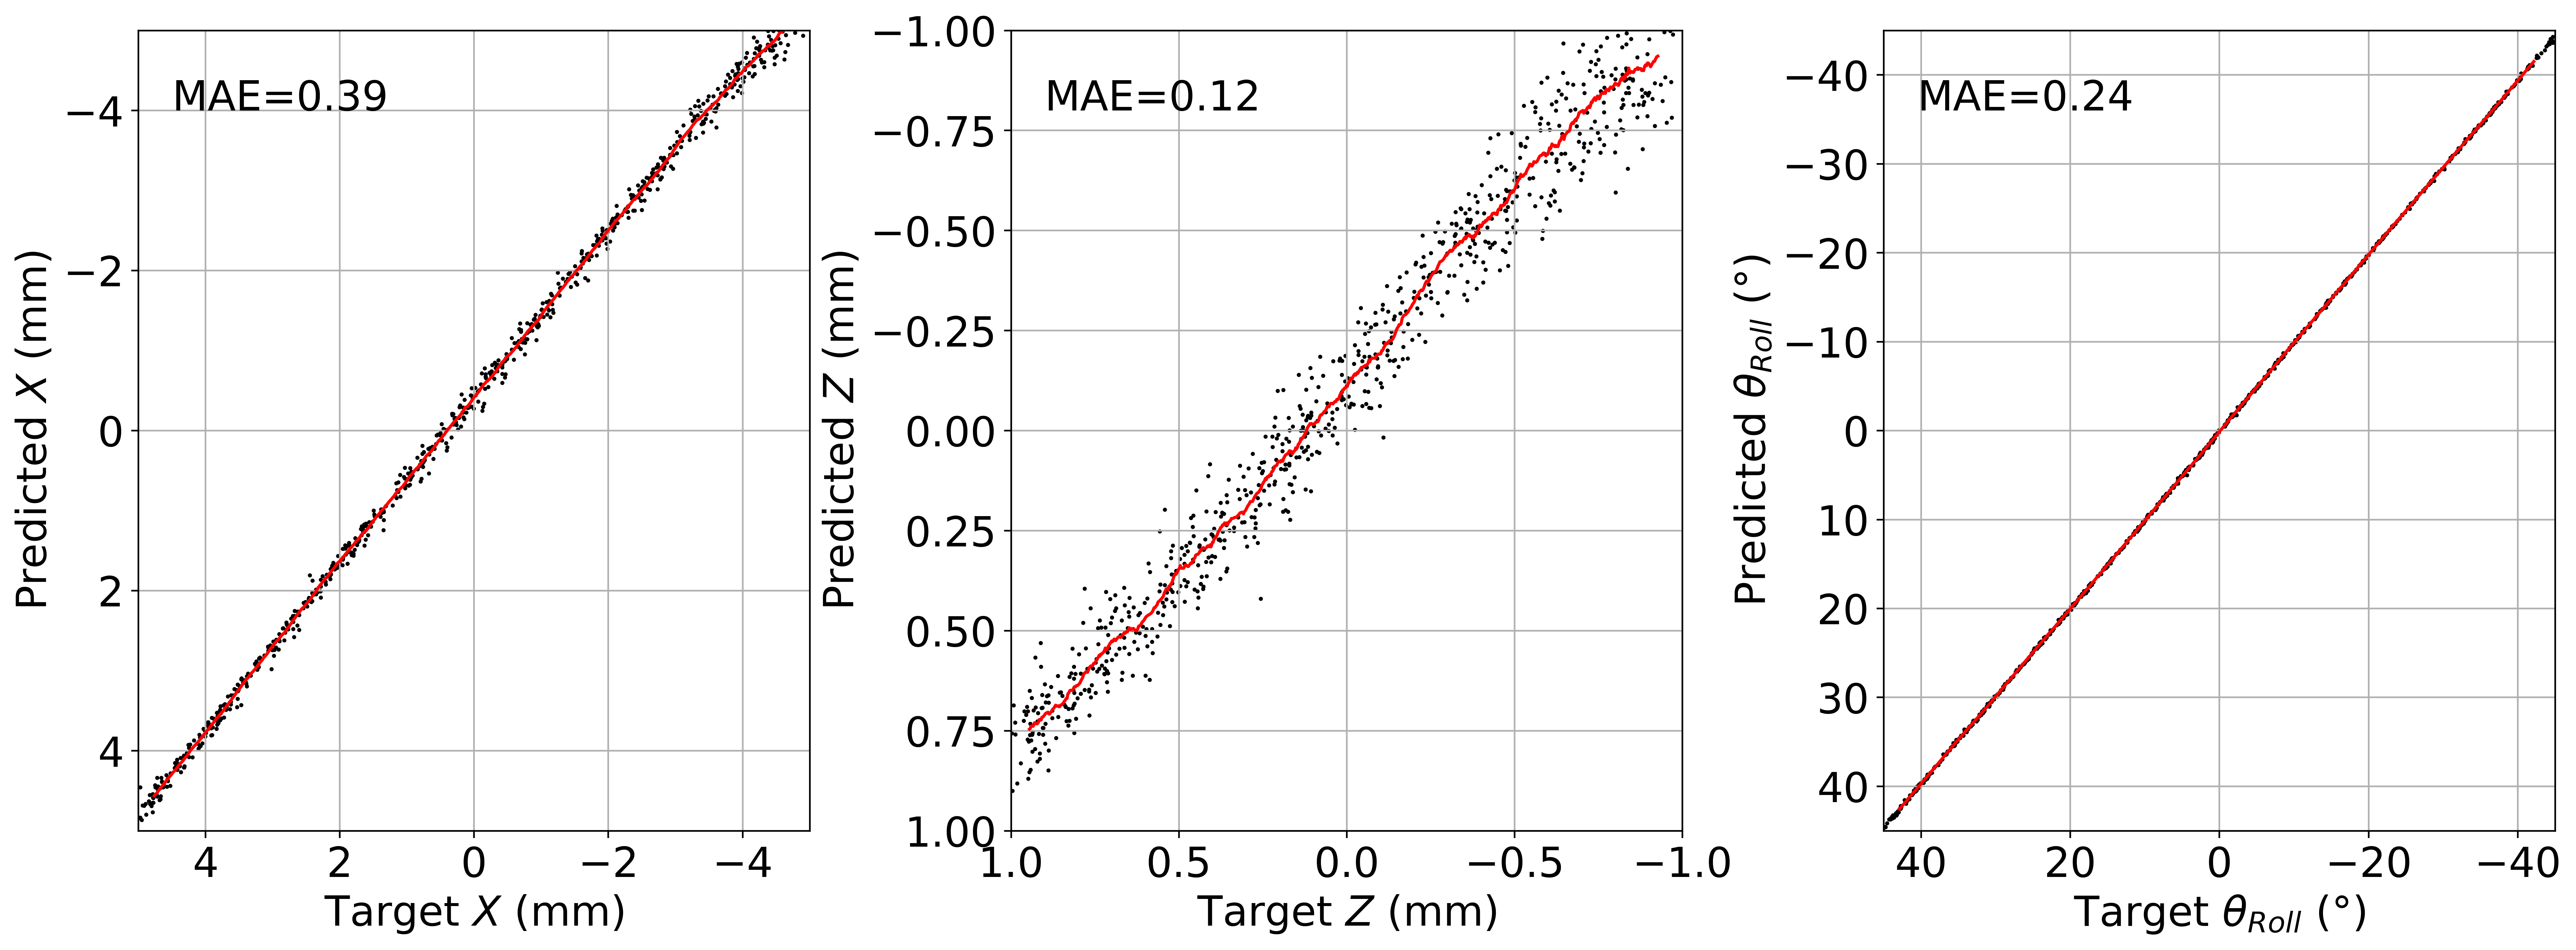

In [8]:
check_gpu(gpu_index=0)
densenet = Densenet_model()
Model, DEVICE = densenet.build_model()
Model.to(DEVICE)

best_model_dir = model_dir + '/best_model.pth'
Model.load_state_dict(torch.load(best_model_dir))

epoch_num=1
criterion = nn.L1Loss()  ## MAE Loss
pose_1_norm = 1  ## pose_2 norm scale
pose_3_norm = 1  ## pose_2 norm scale
pose_6_norm = 1  ## pose_6 norm scale

print('Start Test')

for epoch in range(epoch_num):

    densenet.test(Model, DEVICE, test_loader, criterion, pose_1_norm, pose_3_norm, pose_6_norm, model_dir, test_result_dir)

print('\n' + 'Finished Training')